# Generation with base model (no custom oracle)

test

In [1]:
# Please run the following 'pip install' command to install the required libraries
!pip install jupyter ipywidgets loguru py3dmol rdkit pandas 2>/dev/null | tail -n 1

In [2]:
#install pubchemy
!pip install pubchempy 2>/dev/null | tail -n 1

In [3]:
# Importing libraries for 3-D visualization
#import py3Dmol
import ipywidgets as widgets
from IPython.display import display

# Importing libraries from RD-Kit for handling and manipulating chemical data
from rdkit import Chem
from rdkit.Chem import AllChem, Draw, QED, Crippen
from rdkit.Chem.Draw import IPythonConsole
from rdkit.Chem import PandasTools
from rdkit.Chem import rdFingerprintGenerator
from rdkit.Chem.Fingerprints import FingerprintMols
from rdkit import RDLogger
import pubchempy as pcp

RDLogger.DisableLog('rdApp.*')

In [4]:
# custom code
import os
#print(os.getcwd())
import helper
import pandas as pd

In [37]:
import requests

MOLMIM_HOST = 'http://127.0.0.1:8082'

In [1]:
!curl {MOLMIM_HOST}/v1/health/ready

curl: (6) Could not resolve host: MOLMIM_HOST


# Inputs

### 1. Seed - BCS-CN20332

In [6]:
m1 = "Cc1c2SCCC(=O)c2ccc1C(=O)Nc3nnnn3C"
m1_name = "BCS-CV49374"

m1 = "COC(=O)CCNC(=O)C1(C)CC(c2cc(Cl)cc(Cl)c2)=NO1"
m1_name = "BCS-CN20332"

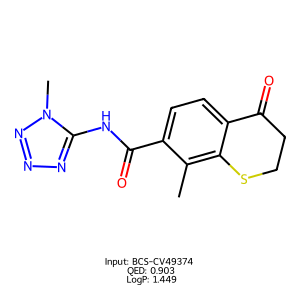

In [7]:
input_mol = Chem.MolFromSmiles(m1)
input_qed = QED.qed(input_mol)
input_logp = Crippen.MolLogP(input_mol)
Draw.MolToImage(input_mol, legend=str(f"Input: {m1_name} \n QED: " + "%.3f" % input_qed + f" \n LogP: " + "%.3f" % input_logp), subImgSize=(350,360))

### 2. Seed - BCS-CE65417

In [11]:
m2 = "CC1=NN(CC)C=C1CNC(=O)C1CC(=NO1)C1C=C(Br)C=CC=1"
m2_name = "BCS-CE65417"

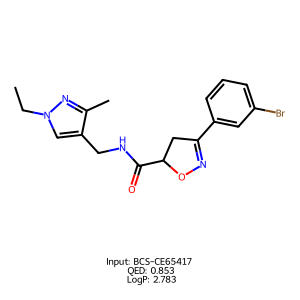

In [12]:
input_mol = Chem.MolFromSmiles(m2)
input_qed = QED.qed(input_mol)
input_logp = Crippen.MolLogP(input_mol)
Draw.MolToImage(input_mol, legend=str(f"Input: {m2_name} \n QED: " + "%.3f" % input_qed + f" \n LogP: " + "%.3f" % input_logp), subImgSize=(350,360))

### Generation #1

In [169]:
# Inferencsing using MolMIM for compound generation
molmim_response = requests.post(
    f'{MOLMIM_HOST}/generate',
    json={
        'smi': m1,
        'num_molecules': 100,
        'algorithm': 'CMA-ES',
        'property_name': 'plogP', # QED or plogP
        'minimize': True,
        'min_similarity': 0.3, # Ignored if algorithm is not "CMA-ES". #max 0.7
        'iterations': 20,
        'particles': 100,
    }).json()

In [170]:
molmim_response

{'generated': [{'smiles': 'COC(=O)CCNC(=O)C1=NNC(=O)C1(c2ccccc2)CC1',
   'score': -100.0},
  {'smiles': 'COC(=O)CCNC(=O)C12CC3CC(CC(C3)C1)C2',
   'score': -7.696139928869564},
  {'smiles': 'COC(=O)CCNC(=O)[C@H]1[C@@H]2CCC(=O)N[C@H]21',
   'score': -2.701490404382016},
  {'smiles': 'CC(=O)NCCNC(=O)C1(N)CC2(CC(CN)C2)C1',
   'score': -2.682635889069793},
  {'smiles': 'COC(=O)CCNC(=O)C1(N)CC2(CC(N)C2)C1',
   'score': -2.5256060264618885},
  {'smiles': 'COC(=O)CCNC(=O)C1(N)CC2(CC(CN)C2)C1',
   'score': -2.332651249620982},
  {'smiles': 'COC(=O)CCNC(=O)C1(N)CC2(CC(CN)C2)C1',
   'score': -2.332651249620982},
  {'smiles': 'COC(=O)CCNC(=O)C1(N)CC2(CC(CN)C2)C1',
   'score': -2.332651249620982},
  {'smiles': 'COC(=O)C1=C(C)OC2(CCCC2)[C@@H]1[C@H](N)Cc1ccn(C)n1',
   'score': -1.9977053400294476},
  {'smiles': 'COC(=O)C1=C(C)OC2(CCCC2)[C@@H]1C(N)=O',
   'score': -1.9435875506548932},
  {'smiles': 'COC(=O)CCNC(=O)C1(N)CC2(CC(F)C2)C1',
   'score': -1.9038362152029609},
  {'smiles': 'COC(=O)CCNC(=O)C1(

Total unique molecule designs obtained: 19


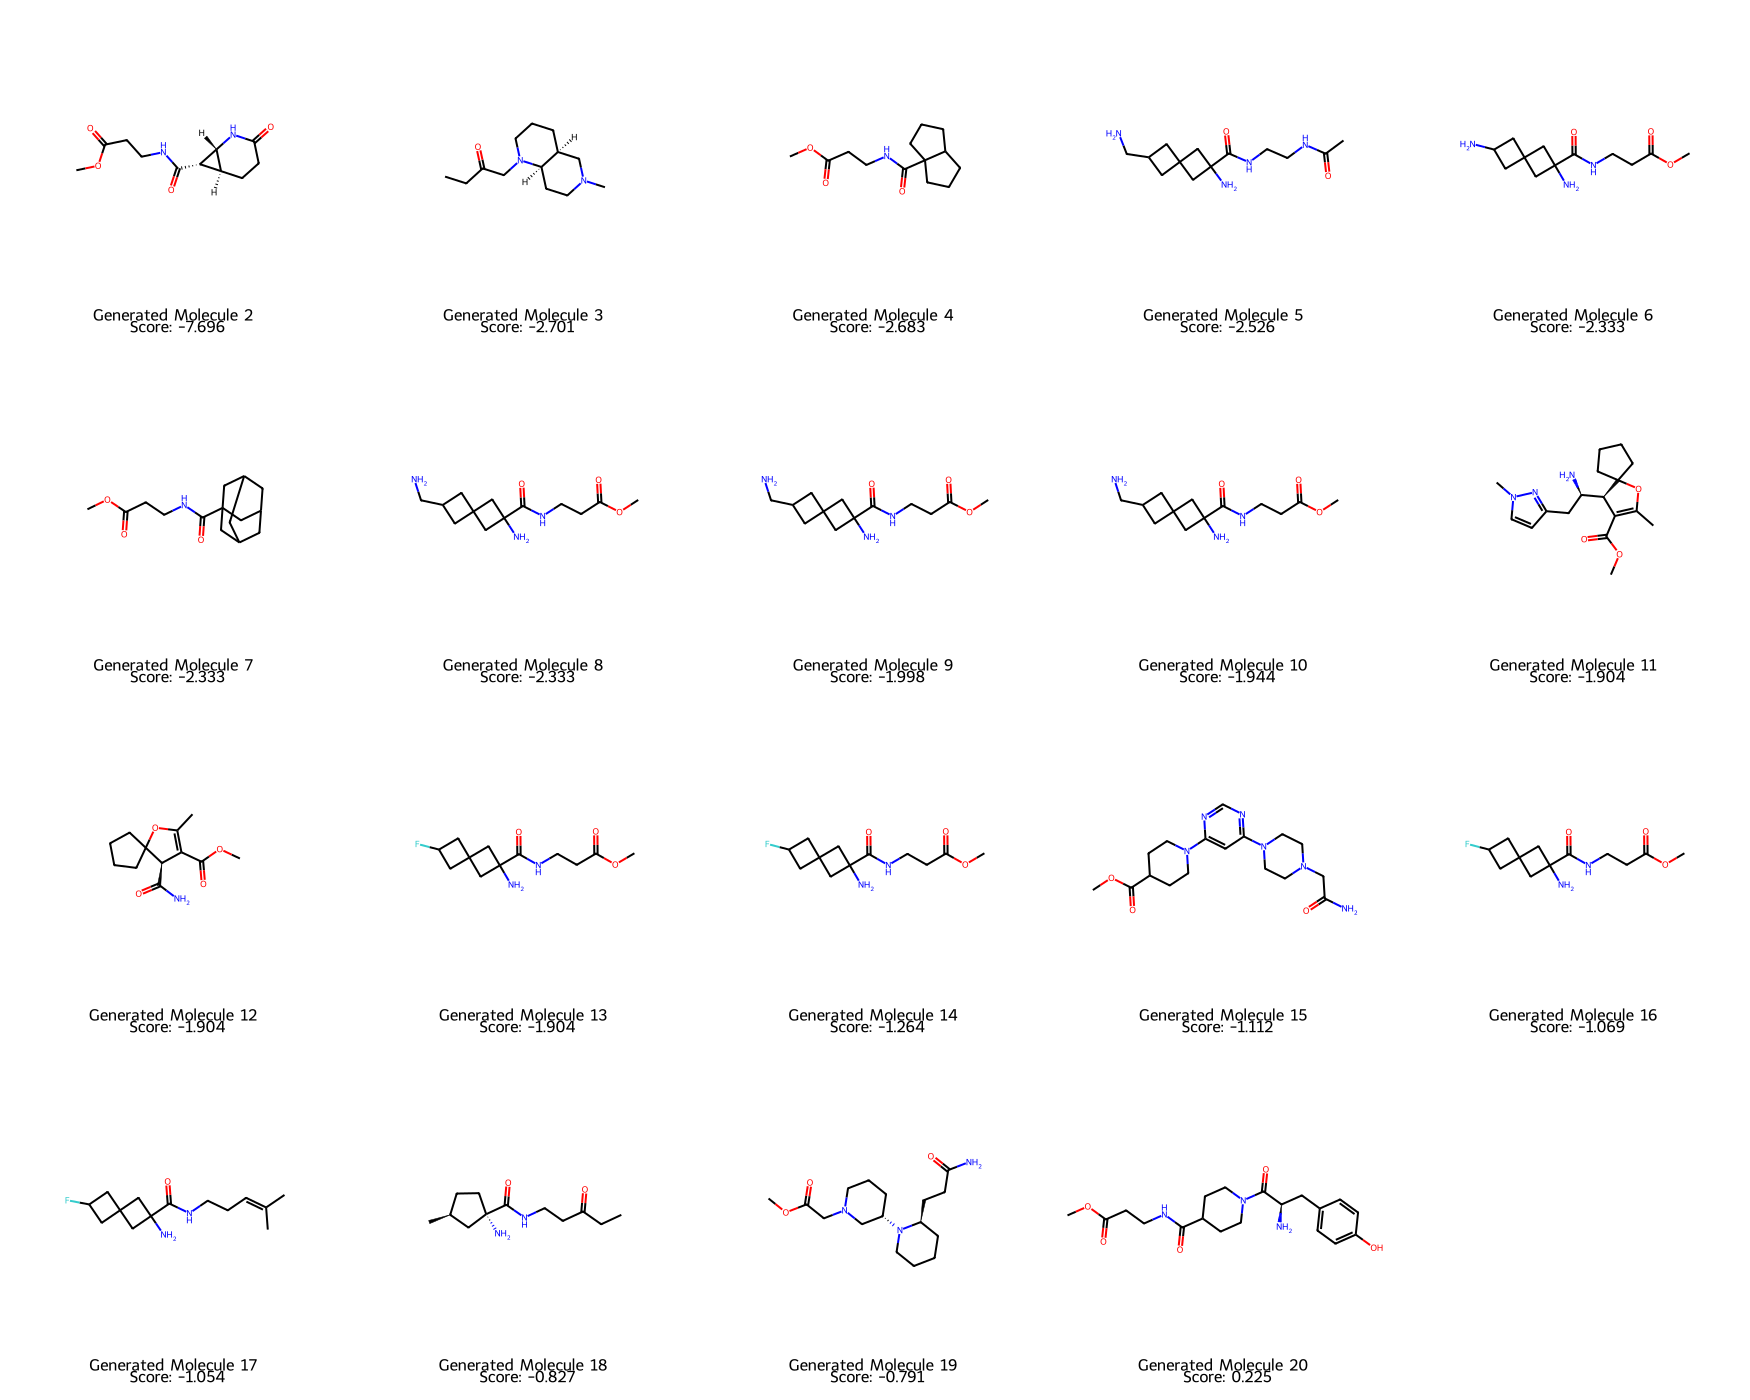

In [174]:
helper.visualize_molecules(molmim_response)

In [175]:
df2 = helper.df_from_molmim_response(molmim_response)
df2['LogP'] = df2['smiles'].apply(helper.calculate_logp)
df2['QED'] = df2['smiles'].apply(helper.calculate_qed)

In [176]:
len(df2.smiles.unique())

16

In [177]:

result_df = pd.concat([result_df, df2], ignore_index=True)

In [178]:
result_df.shape

(120, 4)

In [179]:
len(result_df.smiles.unique())

75

In [182]:
result_df.tail(40)

,smiles,score,LogP,QED
80,COC(=O)CCNC(=O)C1(C)CC(N)(C(N)=O)C1,-2.217668,-1.35140,0.525009
81,COC(=O)CCNC(=O)C1(C)CC(N)(CO)C1,-1.884272,-0.84440,0.547051
82,COC(=O)CCNC(=O)C1(C)CC(N)(CO)C1,-1.884272,-0.84440,0.547051
83,COC(=O)CCNC(=O)C1(C)CC(N)(CO)C1,-1.884272,-0.84440,0.547051
84,COC(=O)CCNC(=O)C1(C)CC(N)(CO)C1,-1.884272,-0.84440,0.547051
85,COC(=O)CCNC(=O)C1(C)CC(N)(CO)C1,-1.884272,-0.84440,0.547051
86,COC(=O)CCNC(=O)C1(C)CC(N)(C(=O)O)C1,-1.705934,-0.75210,0.558073
87,COC(=O)CCNC(=O)C1(C)CC(N)(C(F)F)C1,-1.218768,0.42840,0.705438
88,COC(=O)CCNC(=O)C1(C)CC(N)C1,-1.132784,-0.20690,0.634558
89,COC(=O)CCNC(=O)C1(C)CC(N)C1,-1.132784,-0.20690,0.634558


In [183]:
#result_df.to_csv('../../data/interim/XXX.csv', index=False, sep=';', header=True) #../../data/interim/molmmim_BCS-CN20332_LogP_sim03_100p_100m

In [79]:
result_df_exp1 = result_df.copy()

In [80]:
result_df_exp1.head()

,smiles,score,LogP,QED
0,COC(=O)CCNC(=O)C1(c2cc(C)cc(Cl)c2)CC1,0.848546,2.35932,0.848546
1,CCC(=O)CCNC(=O)C1(C)CC(c2cc(Cl)cc(Cl)c2)C1,0.834751,4.36250,0.834751
2,COC(=O)CCNC(=O)C1(C)CC(c2cc(Cl)cc(Cl)c2)C1,0.831315,3.55640,0.831315
3,COC(=O)CCNC(=O)C1(C)CC(c2cc(Cl)cc(Cl)c2)C1,0.831315,3.55640,0.831315
4,COC(=O)CCNC(=O)C1(C)CC(c2cc(Cl)cc(Cl)c2)C1,0.831315,3.55640,0.831315


In [49]:
len(df.smiles.unique())

11

In [ ]:
df1 = helper.df_from_molmim_response(molmim_response)
df1['LogP'] = df1['smiles'].apply(helper.calculate_logp)
df1['QED'] = df1['smiles'].apply(helper.calculate_qed)

### Generation #2

In [40]:
# Inferencsing using MolMIM for compound generation
molmim_response2 = requests.post(
    f'{MOLMIM_HOST}/generate',
    json={
        'smi': m2,
        'num_molecules': 10,
        'algorithm': 'CMA-ES',
        'property_name': 'plogP', # QED or plogP
        'minimize': False,
        'min_similarity': 0.35, # Ignored if algorithm is not "CMA-ES". #max 0.7
        'iterations': 20,
        'particles': 50,
    }).json()

Total unique molecule designs obtained: 10


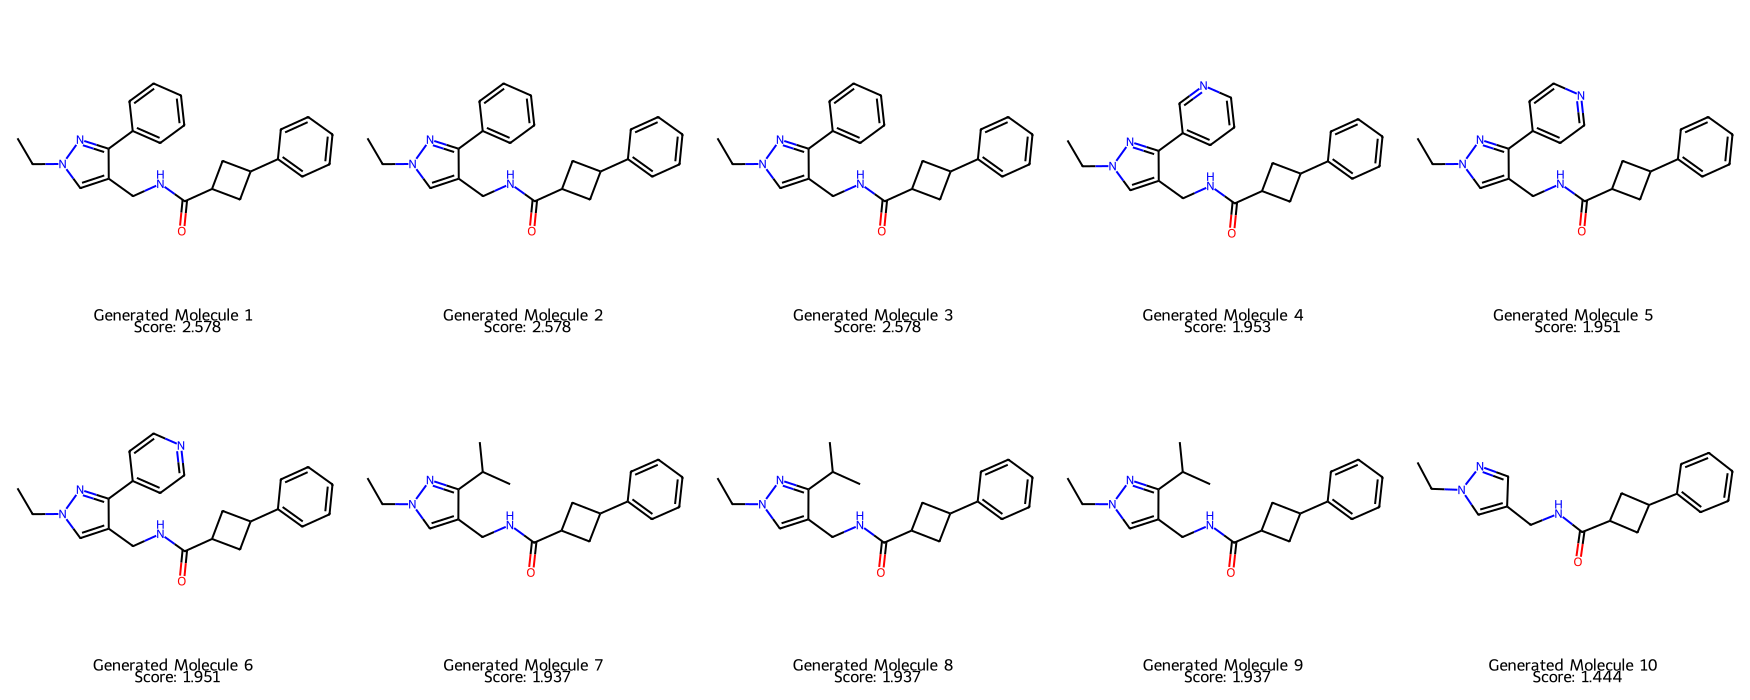

In [44]:
helper.visualize_molecules(molmim_response2)

In [42]:
molmim_response2

{'generated': [{'smiles': 'CCn1cc(CNC(=O)C2CC(c3ccccc3)C2)c(-c2ccccc2)n1',
   'score': 2.577802062159283},
  {'smiles': 'CCn1cc(CNC(=O)C2CC(c3ccccc3)C2)c(-c2ccccc2)n1',
   'score': 2.577802062159283},
  {'smiles': 'CCn1cc(CNC(=O)C2CC(c3ccccc3)C2)c(-c2ccccc2)n1',
   'score': 2.577802062159283},
  {'smiles': 'CCn1cc(CNC(=O)C2CC(c3ccccc3)C2)c(-c2cccnc2)n1',
   'score': 1.9531213359326007},
  {'smiles': 'CCn1cc(CNC(=O)C2CC(c3ccccc3)C2)c(-c2ccncc2)n1',
   'score': 1.9505209738600973},
  {'smiles': 'CCn1cc(CNC(=O)C2CC(c3ccccc3)C2)c(-c2ccncc2)n1',
   'score': 1.9505209738600973},
  {'smiles': 'CCn1cc(CNC(=O)C2CC(c3ccccc3)C2)c(C(C)C)n1',
   'score': 1.9372259561476441},
  {'smiles': 'CCn1cc(CNC(=O)C2CC(c3ccccc3)C2)c(C(C)C)n1',
   'score': 1.9372259561476441},
  {'smiles': 'CCn1cc(CNC(=O)C2CC(c3ccccc3)C2)c(C(C)C)n1',
   'score': 1.9372259561476441},
  {'smiles': 'CCn1cc(CNC(=O)C2CC(c3ccccc3)C2)cn1', 'score': 1.44402550357782}]}

In [34]:
df = helper.df_from_molmim_response(molmim_response2)
df['LogP'] = df['smiles'].apply(helper.calculate_logp)
df['QED'] = df['smiles'].apply(helper.calculate_qed)

In [35]:
df.head()

,smiles,score,LogP,QED
0,CCn1cc(C(=O)NCC2CN(Cc3ccc([C@@H]4C[C@H]4C)o3)C...,-0.667609,1.87620,0.830543
1,CCn1cc(CC(=O)OC2CN(c3cccc(Br)c3)C2)c(C)n1,1.109199,2.94842,0.751077
2,CCn1cc(CNC(=O)C2CN(c3cccc(Br)c3)C2)c(C)n1,1.220193,2.72652,0.871971
3,CCn1cc(CNC(=O)C2CN(c3cccc(Br)c3)C2)c(C)n1,1.220193,2.72652,0.871971
4,CCn1cc(CNC(=O)C2CN(c3cccc(Br)c3)C2)c(C)n1,1.220193,2.72652,0.871971
